![Banner](../../../../Images/Banner/07_remote_sensing/09_02_banner_rs_optical.png)


# Sentinel-3: Ocean Colour, Surface Temperature and Altimetry

Sentinel-3 (Copernicus, ESA/EUMETSAT) is four instruments on one platform: OLCI for ocean and land colour, SLSTR for sea and land surface temperature and fire, SRAL for sea-surface height, and a microwave radiometer that corrects the altimeter.


## Overview

Two satellites in orbit give global ocean coverage in under two days. This module works with real OLCI and SLSTR products downloaded live from Microsoft Planetary Computer.


## Core concepts

### Learning objectives

1. Know the four Sentinel-3 instruments, their products, and the NRT/STC/NTC timeliness levels.
2. Decode any Sentinel-3 quality flag from its own `flag_masks`/`flag_meanings` metadata, rather
   than a hardcoded bit position.
3. Read and mask a real OLCI Level-2 water product, and understand why a standard ocean flag can
   misbehave over turbid inland water.
4. Back-transform a log-scaled chlorophyll product and resample it from swath to a regular grid.
5. Read and mask a real SLSTR Level-2 land surface temperature product.
6. Read SLSTR fire radiative power, keep vegetation fires, and map where forest was actively burning.
7. Know when a land-targeted index (OTCI) breaks down outside its intended domain.

### Contents

1. The mission
2. Platforms
3. Sensors
4. Spectral bands
5. Data products
6. Applications
7. Where to get the data
8. Swath products
9. Data
10. Setup
11. The Sentinel-3 product family and the CF flag convention
12. Downloading a real OLCI water product
13. Reading and masking OLCI L2 water data
14. Chlorophyll retrieval: log back-transform and swath-to-grid
15. Mapping a harmful algal bloom
16. SLSTR land surface temperature
17. Active forest fires in western Canada
18. Terrestrial chlorophyll indices, in and out of their domain
19. Summary, exercises and references


## The mission

Sentinel-3 is the Copernicus mission for global ocean, land, ice, and atmosphere monitoring. It measures:
  - Sea surface temperature, ocean colour, and sea level
  - Land cover and other environmental indicators for climate monitoring
- **Heritage.** Sentinel-3 continues observations from earlier ESA and French missions:
  - **Envisat** (2002 to 2012): MERIS (ocean colour), AATSR (surface temperature), and RA-2 (altimetry)
  - **ERS-1 and ERS-2**: ATSR series
  - **SPOT-VEGETATION and PROBA-V**: vegetation monitoring, continued through Sentinel-3's synergy products
- **Development.** ESA develops the satellites on behalf of the European Commission. Thales Alenia Space is the prime contractor.
- **Operations split**
  - **EUMETSAT** flies the satellites and produces the marine products.
  - **ESA** produces the land products.
- **Launch timeline**
  - Sentinel-3A launched on 16 February 2016 on a Rockot from Plesetsk, Russia.
  - Sentinel-3B launched on 25 April 2018, also on a Rockot.
  - Sentinel-3C launched on 15 September 2026 on a Vega C from Kourou (mission VV30), sharing the ride with ESA's FLEX fluorescence satellite. It returned its first images in late September 2026 and is currently in commissioning.
  - Sentinel-3D is planned for 2028.
  - A next-generation mission is planned for the 2030s: Sentinel-3 Next Generation Optical, plus a separate topography mission.


## Platforms

- **Constellation.** Two satellites operate together. Sentinel-3A and 3B fly in the same orbit about 140° apart. Sentinel-3C will join them and eventually take over from 3A.
- **Spacecraft.** About 1,150 kg each, with a design life of about 7 years and fuel for roughly 12.
- **Orbit**
  - Sun-synchronous at about 815 km altitude.
  - Equatorial crossing at 10:00 a.m. local time (descending node). The early-morning crossing reduces cloud and sun-glint effects over the ocean.
  - 27-day repeat cycle, which is set by the altimetry ground track.
- **Revisit with two satellites**
  - OLCI: less than 2 days globally, and about daily at mid-latitudes.
  - SLSTR: about daily in the dual view, and better than daily in the nadir view.
  - Altimetry: 27-day repeat. With two satellites, the tracks are interleaved, which gives a denser spatial grid of measurements.


## Sensors

Each satellite carries four main instrument packages.

**1. Ocean and Land Colour Instrument (OLCI)**
- Push-broom imaging spectrometer that succeeds MERIS.
- 21 bands from 400 to 1020 nm.
- Resolution: 300 m in Full Resolution (FR) mode; 1.2 km in Reduced Resolution (RR) mode.
- 1,270 km swath from 5 cameras. The view is tilted 12.6° westward to reduce sun glint.

**2. Sea and Land Surface Temperature Radiometer (SLSTR)**
- Dual-view conical scanner that succeeds AATSR.
- 9 spectral bands plus 2 dedicated fire channels.
- Resolution: 500 m in the visible/SWIR; 1 km in the thermal infrared.
- Two views of each location:
  - Nadir view with a 1,400 km swath
  - Oblique (backward) view with a 740 km swath
- Combining the two views gives very accurate atmospheric correction for sea surface temperature, accurate to about 0.3 K.

**3. Synthetic Aperture Radar Altimeter (SRAL)**
- Dual-frequency radar altimeter (Ku-band at 13.575 GHz and C-band at 5.41 GHz).
- Operates in SAR (delay-Doppler) mode with about 300 m along-track resolution, which makes it suitable for coastal zones, rivers, lakes, and sea ice.

**4. Supporting packages**
- **Microwave Radiometer (MWR).** Measures at 23.8 and 36.5 GHz to correct the altimeter for atmospheric water vapour (wet troposphere correction).
- **Precise Orbit Determination (POD).** GNSS receiver, DORIS, and a laser retroreflector, giving orbits accurate to the centimetre for sea-level measurement.


## Spectral bands

### OLCI (21 bands; 300 m FR / 1.2 km RR)

| Band | Centre (nm) | Width (nm) | Main use |
|---|---|---|---|
| Oa01 | 400 | 15 | Aerosol, improved water constituent retrieval |
| Oa02 | 412.5 | 10 | Yellow substance (CDOM), detritus |
| Oa03 | 442.5 | 10 | Chlorophyll absorption maximum |
| Oa04 | 490 | 10 | High chlorophyll, other pigments |
| Oa05 | 510 | 10 | Chlorophyll, sediment, turbidity, red tide |
| Oa06 | 560 | 10 | Chlorophyll reference (minimum absorption) |
| Oa07 | 620 | 10 | Sediment loading, phycocyanin |
| Oa08 | 665 | 10 | Chlorophyll (second absorption maximum), sediment |
| Oa09 | 673.75 | 7.5 | Improved fluorescence retrieval |
| Oa10 | 681.25 | 7.5 | Chlorophyll fluorescence peak, red edge |
| Oa11 | 708.75 | 10 | Fluorescence baseline, red edge |
| Oa12 | 753.75 | 7.5 | O₂ absorption reference, cloud, vegetation |
| Oa13 | 761.25 | 2.5 | O₂ absorption (cloud top pressure, aerosol) |
| Oa14 | 764.375 | 3.75 | Atmospheric correction |
| Oa15 | 767.5 | 2.5 | O₂ A-band (cloud top pressure, fluorescence) |
| Oa16 | 778.75 | 15 | Atmospheric correction, aerosol, vegetation |
| Oa17 | 865 | 20 | Atmospheric correction, cloud, vegetation |
| Oa18 | 885 | 10 | Water vapour reference, vegetation |
| Oa19 | 900 | 10 | Water vapour absorption |
| Oa20 | 940 | 20 | Water vapour absorption |
| Oa21 | 1020 | 40 | Atmospheric correction, aerosol |

### SLSTR (9 bands plus 2 fire channels)

| Band | Centre (µm) | Resolution | Main use |
|---|---|---|---|
| S1 | 0.555 | 500 m | Cloud screening, vegetation |
| S2 | 0.659 | 500 m | NDVI, vegetation, aerosol |
| S3 | 0.865 | 500 m | NDVI, cloud, pixel co-registration |
| S4 | 1.375 | 500 m | Cirrus detection |
| S5 | 1.610 | 500 m | Cloud clearing, ice, snow, vegetation moisture |
| S6 | 2.250 | 500 m | Vegetation state, cloud clearing |
| S7 | 3.74 | 1 km | Sea and land surface temperature, active fire |
| S8 | 10.85 | 1 km | Sea and land surface temperature, active fire |
| S9 | 12.0 | 1 km | Sea and land surface temperature |
| F1 | 3.74 | 1 km | Active fire (high saturation level) |
| F2 | 10.85 | 1 km | Active fire |

**Common indices:**
- OTCI (OLCI Terrestrial Chlorophyll Index) = (Oa12 − Oa11)/(Oa11 − Oa10)
- NDVI from OLCI = (Oa17 − Oa08)/(Oa17 + Oa08)
- Maximum Chlorophyll Index (MCI) uses Oa10 to Oa12, for detecting algal blooms.


## Data products

**Timeliness categories:**
- **NRT (Near Real Time):** within 3 hours.
- **STC (Short Time Critical):** within 48 hours. Used for altimetry.
- **NTC (Non Time Critical):** within about 1 month. Best quality; recommended for science.

| Instrument | Level | Product | Content |
|---|---|---|---|
| **OLCI** | L1B | `OL_1_EFR` / `OL_1_ERR` | TOA radiances at 300 m / 1.2 km |
| | L2 Land | `OL_2_LFR` / `OL_2_LRR` | GIFAPAR (formerly OGVI), OTCI, integrated water vapour, rectified reflectance |
| | L2 Water | `OL_2_WFR` / `OL_2_WRR` | Water-leaving reflectance, chlorophyll-a (OC4ME, NN), total suspended matter (TSM), Kd490, CDOM, PAR, aerosol |
| **SLSTR** | L1B | `SL_1_RBT` | Radiances and brightness temperatures, nadir and oblique views |
| | L2 Land | `SL_2_LST` | Land surface temperature (1 km) |
| | L2 Marine | `SL_2_WST` | Sea surface temperature (GHRSST L2P format) |
| | L2 | `SL_2_FRP` | Fire radiative power (active fires) |
| | L2 | `SL_2_AOD` | Aerosol optical depth |
| **SRAL/MWR** | L1/L2 | `SR_1_SRA`, `SR_2_WAT` (marine), `SR_2_LAN` (land) | Sea surface height, significant wave height, wind speed, inland water height, sea ice freeboard, land ice elevation |
| **Synergy** (OLCI + SLSTR) | L2 | `SY_2_SYN` | Surface reflectance and AOD at 300 m |
| | L2 | `SY_2_VGP`, `SY_2_VG1`, `SY_2_V10` | VEGETATION-like products (1-day and 10-day composites); continuity with SPOT-VGT and PROBA-V |

- **Format.** SAFE container with NetCDF-4 files, plus an `xfdumanifest.xml` file.
- **Geometry.** Level-1 and Level-2 products are delivered in instrument geometry with latitude/longitude arrays. They are not map-projected, so you need to reproject them, for example with SNAP or `satpy`.
- **Naming.** File names follow the pattern `S3A_OL_1_EFR____<start>_<stop>_...`. The fields encode the satellite, instrument, level, and product.
- **Downstream products**
  - Copernicus Marine Service: ocean colour, SST, and sea level L3/L4 products
  - Copernicus Land Monitoring Service: LST, NDVI, FAPAR, lake water quality, and river and lake water levels
  - Copernicus Climate Change Service and ESA Climate Change Initiative (CCI) records


## Applications

- **Ocean**
  - Ocean colour, phytoplankton, and primary productivity
  - Harmful algal blooms and cyanobacteria
  - Sea surface temperature for weather and climate models
  - Sea level rise and ocean currents
  - Wave height and wind speed
- **Coastal and inland water**
  - Turbidity and sediment plumes
  - Lake water quality (chlorophyll, CDOM)
  - River and reservoir water levels from SAR altimetry
- **Cryosphere.** Sea ice extent and freeboard (thickness), ice sheet elevation change, snow cover.
- **Land**
  - Land surface temperature, drought, and heat stress
  - Vegetation condition (OTCI, FAPAR, NDVI)
  - Regional crop monitoring
  - Land cover
- **Fire.** Active fire detection and fire radiative power (FRP) for emissions estimates.
- **Atmosphere.** Aerosol optical depth, dust and smoke transport, total column water vapour.
- **Weather and climate**
  - Inputs to numerical weather prediction and ocean forecasting systems
  - Long-term records for climate change monitoring
- **Environment and health**
  - Urban heat exposure from LST
  - Algal bloom risk for drinking water and recreation
  - Smoke exposure from wildfires
  - Vector habitat linked to surface temperature and vegetation


## Where to get the data

Sentinel-3 data are **free and open** under the Copernicus data policy.

| Platform | Notes |
|---|---|
| **Copernicus Data Space Ecosystem** (dataspace.copernicus.eu) | All land and marine products. Offers Copernicus Browser, OData/STAC APIs, openEO, and Sentinel Hub processing. |
| **EUMETSAT Data Store** | Marine products: OLCI water, SLSTR SST, SRAL marine |
| **EUMETCast** | Near-real-time satellite broadcast of marine products |
| **Copernicus Marine Service** (marine.copernicus.eu) | Gridded L3/L4 ocean colour, SST, and sea level |
| **Copernicus Land Monitoring Service** | LST, vegetation, and water bodies |
| **Google Earth Engine** | `COPERNICUS/S3/OLCI` (OLCI L1B EFR radiances only) |
| **NASA Ocean Biology DAAC** (oceancolor.gsfc.nasa.gov) | OLCI data reprocessed with NASA algorithms |

**Software and Python tools:**
- **SNAP Sentinel-3 Toolbox** (ESA): reprojection, mosaicking, C2RCC water processing
- `satpy` and `pyresample`: reading and reprojecting swath data
- `eumdac`: EUMETSAT Data Store API
- `xarray` with `netCDF4` or `h5netcdf`: reading product files
- `openeo` and `sentinelhub`: cloud processing
- `pystac-client`: STAC search on CDSE

**Practical tips:**
- Use NTC products for research.
- Apply the quality flags in each product:
  - `WQSF` for OLCI water products
  - `LQSF` for OLCI land products
  - Confidence and cloud flags for SLSTR
- Reproject from swath geometry before combining with gridded data.
- For land work at higher spatial resolution, pair Sentinel-3 with Sentinel-2 or Landsat.

Sources:
- [Sentinel-3C, Wikipedia](https://en.wikipedia.org/wiki/Sentinel-3C)
- [Countdown to Launch: Copernicus Sentinel-3C, EU Space](https://eu-space.europa.eu/news/countdown-launch-copernicus-sentinel-3c-takes-flight-14-september)
- [Sentinel-3C launch in September, Sigmalive](https://en.sigmalive.com/sentinel-3c-launch-in-september-set-to-strengthen-earth-observation/)
- [Copernicus Sentinel-3C expected launch, Open Access Government](https://www.openaccessgovernment.org/copernicus-sentinel-3c-expected-launch-september-helping-monitor-earth/212693/)
- [Copernicus mission status, SIOS](https://www.sios-svalbard.org/CopernicusRelay)


## Swath products

GeoLattice provides reader, flag-decoding and swath-to-grid regridding functions for Sentinel-3's
OLCI, SLSTR, SRAL and Synergy products through `geolattice.rsense.optical.sensors.sentinel3`. Unlike
the other optical sensors in this module, Sentinel-3 products are NetCDF-4 files in satellite
swath geometry rather than georeferenced COGs, so this notebook downloads real product files
directly from Microsoft Planetary Computer's STAC catalogue and works with them using the
standard Sentinel-3 workflow: read, mask by quality flags, convert units, then resample from
swath to a map grid.


## Data

| Dataset | Content |
|---|---|
| OLCI L2 WFR, downloaded live from Planetary Computer | 2 dates (5 and 19 September 2023), western Lake Erie, late-summer harmful algal bloom season |
| SLSTR L2 LST, downloaded live from Planetary Computer | 1 date (15 July 2023, nighttime overpass), Las Vegas valley |
| SLSTR L2 FRP, downloaded live from Planetary Computer | 16 May 2023, Alberta and Saskatchewan, early peak of the 2023 wildfire season |


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. "mean of empty slice" in all-NaN areas

import json  # read metadata
from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters (Sentinel-3 products are NetCDF)
import matplotlib.pyplot as plt  # figures
import requests  # download files over HTTP
import pystac_client  # STAC search client
import planetary_computer as pc  # signs Planetary Computer URLs

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.optical.sensors import sentinel3 as s3  # Sentinel-3 readers, flags and FRP tools
from geolattice.network import is_online  # internet check

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")  # can Planetary Computer be reached?
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"),  # version and backend
      "| Planetary Computer reachable:", ONLINE)

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_02_optical/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_02_optical"), Path("../../../../Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))
DATA.mkdir(exist_ok=True)  # create it if needed
# open the Planetary Computer STAC catalogue (with URL signing)
CATALOG = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=pc.sign_inplace)


def local_scenes(folder, files=()):
    """Scene folders already downloaded under `folder` that contain every file in `files`."""
    folder = Path(folder)
    if not folder.is_dir():  # nothing downloaded yet
        return []
    return sorted(p for p in folder.iterdir() if p.is_dir() and all((p / f).exists() for f in files))

geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


## The Sentinel-3 product family and the CF flag convention

Every `geolattice.rsense.optical.sensors.sentinel3` reader takes a folder path (an extracted `.SEN3`
product) and returns the variables you need under short, canonical lowercase names. The table
below is the same product list from the Overview, alongside the `geolattice.rsense` reader and mask
function each one uses. Every mask function works the same way underneath: it reads the matching
flag variable's `flag_masks` and `flag_meanings` attributes and excludes the named bits, so the
same `decode_flags`/`flag_mask` logic covers products whose bit layouts differ completely.


In [2]:
products = pd.DataFrame([  # Sentinel-3 products as a table
    ("OL_1_EFR/ERR", "OLCI L1 radiance", "read_olci_l1", "olci_l1_mask"),
    ("OL_2_LFR/LRR", "OLCI L2 land (FAPAR, OTCI)", "read_olci_land", "olci_land_mask"),
    ("OL_2_WFR/WRR", "OLCI L2 water (chlorophyll, TSM)", "read_olci_water", "olci_water_mask"),
    ("SL_1_RBT", "SLSTR L1 radiance/BT", "read_slstr_l1", "slstr_flag_mask"),
    ("SL_2_LST", "SLSTR land surface temperature", "read_slstr_lst", "slstr_lst_mask"),
    ("SL_2_WST", "SLSTR sea surface temperature", "read_slstr_sst", "sst_quality_mask"),
    ("SL_2_FRP", "SLSTR fire radiative power", "read_slstr_frp", "(point data; see frp_to_points)"),
    ("SR_2_WAT", "SRAL open-ocean altimetry", "read_sral_marine", "sral_marine_mask"),
    ("SR_2_LAN", "SRAL land/ice altimetry", "read_sral_marine", "sral_marine_mask"),
    ("SY_2_SYN", "Synergy OLCI+SLSTR reflectance", "read_synergy", "synergy_mask"),
    ("SY_2_VGP/VG1/V10", "Synergy vegetation (gridded)", "read_synergy_vgt", "n/a (already clean)"),
], columns=["Product", "Content", "Reader", "Mask function"])
products  # show it

,Product,Content,Reader,Mask function
0,OL_1_EFR/ERR,OLCI L1 radiance,read_olci_l1,olci_l1_mask
1,OL_2_LFR/LRR,"OLCI L2 land (FAPAR, OTCI)",read_olci_land,olci_land_mask
2,OL_2_WFR/WRR,"OLCI L2 water (chlorophyll, TSM)",read_olci_water,olci_water_mask
3,SL_1_RBT,SLSTR L1 radiance/BT,read_slstr_l1,slstr_flag_mask
4,SL_2_LST,SLSTR land surface temperature,read_slstr_lst,slstr_lst_mask
5,SL_2_WST,SLSTR sea surface temperature,read_slstr_sst,sst_quality_mask
6,SL_2_FRP,SLSTR fire radiative power,read_slstr_frp,(point data; see frp_to_points)
7,SR_2_WAT,SRAL open-ocean altimetry,read_sral_marine,sral_marine_mask
8,SR_2_LAN,SRAL land/ice altimetry,read_sral_marine,sral_marine_mask
9,SY_2_SYN,Synergy OLCI+SLSTR reflectance,read_synergy,synergy_mask


Decoding a flag never requires knowing which bit means what in advance. `decode_flags`
reads every named bit straight from the variable's own metadata, and `flag_mask` builds a
boolean "keep this pixel" array from a list of flag names to exclude:


In [3]:
help(s3.decode_flags)  # documentation of the flag decoder
help(s3.flag_mask)  # documentation of the flag-mask helper

Help on function decode_flags in module geolattice.rsense.optical.sensors.sentinel3:

decode_flags(flag: 'xr.DataArray') -> 'dict[str, xr.DataArray]'
    Every named bit of a Sentinel-3 flag variable, read from its own metadata.
    
    Uses the variable's ``flag_masks`` and ``flag_meanings`` attributes (CF convention),
    never a hardcoded bit position, since the bit layout differs by product and baseline.

Help on function flag_mask in module geolattice.rsense.optical.sensors.sentinel3:

flag_mask(flag: 'xr.DataArray', exclude: 'Iterable[str]', *, match: 'str' = 'exact') -> 'xr.DataArray'
    Boolean validity mask (``True`` = usable) excluding the named flags.
    
    ``match="exact"`` requires the flag meaning to equal an entry in ``exclude``;
    ``match="contains"`` excludes a flag if any entry in ``exclude`` is a substring of its
    name (handy for SLSTR, whose per-channel flags are named e.g. ``cloud_in``).



## Downloading a real OLCI water product

Western Lake Erie develops seasonal harmful algal blooms (HABs) most summers, driven by
agricultural runoff into the Maumee River. We search Planetary Computer's
`sentinel-3-olci-wfr-l2-netcdf` collection for two late-summer 2023 dates and download the real
product files for each: the default water variables, the `WQSF` quality flag, and the pixel
geolocation (`geo_coordinates.nc`), reproducing the structure of an extracted `.SEN3` folder on
disk so the reader functions below work exactly as they would on a manually downloaded product.
One date also gets three OLCI reflectance bands (`Oa10`, `Oa11`, `Oa12`) for the *Terrestrial chlorophyll indices, in and out of their domain* section.


In [ ]:
# Define the geographical bounding box for the area of interest: Western Lake Erie open water.
ERIE_BBOX = (-83.35, 41.38, -82.55, 41.85)  

# List of dates we want to download Sentinel-3 OLCI water products for.
OLCI_DATES = ["2023-09-05", "2023-09-19"]

# Key OLCI water variables to extract for analysis.
WATER_VARS = ["chl_oc4me", "chl_nn", "tsm_nn", "trsp", "iop_nn"]

# OLCI reflectance bands (used in later sections, only required for the first date).
OA_BANDS = ["oa10", "oa11", "oa12"]                 

# Output directory where downloaded data will be stored.
S3_OUT = DATA / "s3_erie_2023"

# scene folders that already hold every water variable plus the flags and geolocation
erie_local = local_scenes(S3_OUT, [f"{v}.nc" for v in WATER_VARS] + ["wqsf.nc", "geo_coordinates.nc"])
if len(erie_local) >= len(OLCI_DATES):  # one folder per date is on disk
    print("Reading the OLCI scenes already downloaded under", S3_OUT)  # use the local drive
elif ONLINE:  # not on disk yet: download when online
    # Search the Planetary Computer STAC catalog for Sentinel-3 OLCI L2 water products
    # over the given bounding box and date range.
    search = CATALOG.search(
        collections=["sentinel-3-olci-wfr-l2-netcdf"],
        bbox=ERIE_BBOX,
        datetime="2023-09-01/2023-09-20",
        limit=20
    )
    # Index the search results by their observation date.
    items = {it.datetime.date().isoformat(): it for it in search.items()}
    for i, d in enumerate(OLCI_DATES):  # every OLCI date
        it = items[d]  # Get search item for target date.
        scene_dir = S3_OUT / it.id  # Create a separate folder for each product.
        scene_dir.mkdir(exist_ok=True, parents=True)  # its folder
        # Create a mapping of asset keys to their destination filenames for water variables.
        assets = {f"{v.replace('_', '-')}": f"{v}.nc" for v in WATER_VARS}
        # Always add quality flags and geolocation files.
        assets.update({"wqsf": "wqsf.nc", "geo-coordinates": "geo_coordinates.nc"})
        # For the first date, also download the reflectance bands.
        if i == 0:
            # the reflectance NetCDF of every band
            assets.update({b: f"Oa{b[2:]}_reflectance.nc" for b in OA_BANDS})
        # Download each asset file if it's not already present.
        for key, fname in assets.items():
            dest = scene_dir / fname  # local file
            if dest.exists():  # skip files already downloaded
                continue  # Skip if already downloaded.
            r = requests.get(it.assets[key].href, timeout=60)  # download the asset
            r.raise_for_status()  # Raise an error on connection/HTTP failure.
            dest.write_bytes(r.content)  # Write the file to disk.
        # Print confirmation after downloading each product.
        print(d, it.id, "downloaded")
else:
    # If not downloading (e.g. offline), notify about reusing existing data on disk.
    print("Offline: reusing the scenes already downloaded under", S3_OUT)

2023-09-05 S3B_OL_2_WFR_20230905T155540_20230905T155840_0179_083_325_2160 downloaded
2023-09-19 S3A_OL_2_WFR_20230919T153401_20230919T153701_0180_103_282_2340 downloaded


## Reading and masking OLCI L2 water data

`read_olci_water` opens the five default water variables plus `WQSF` and geolocation, and
renames each from its real file variable name (`CHL_NN`, `KD490_M07`, ...) to the documented
canonical name. `olci_water_mask` then builds a validity mask from `WQSF`.


In [9]:
# List all subdirectories in the output directory, which each correspond to a downloaded Sentinel-3 scene.
scene_dirs = sorted(p for p in S3_OUT.iterdir() if p.is_dir())

# Read the OLCI water data from the first available scene directory using the provided helper.
ds0 = s3.read_olci_water(scene_dirs[0])

# Display the names of the variables contained in the dataset.
print("Variables:", list(ds0.data_vars))

# Print the size (number of elements) for each dimension in the dataset to show its shape.
print("Shape:", dict(ds0.sizes))

Variables: ['chl_oc4me', 'chl_oc4me_err', 'chl_nn', 'chl_nn_err', 'tsm_nn', 'tsm_nn_err', 'trsp', 'trsp_err', 'iop_nn', 'iop_nn_err', 'wqsf']
Shape: {'rows': 4091, 'columns': 4865}


`WQSF`'s default exclusion list includes a `LAND` flag, appropriate for open ocean, where
it reliably separates water from coastline. Over a turbid, algae-rich inland lake like western
Lake Erie it misfires: the land/water discrimination algorithm reads the lake's high-sediment,
high-chlorophyll reflectance as land far more often than it should. Checking the flag breakdown
inside our own AOI shows this directly.


In [ ]:
# Extract longitude and latitude arrays from the dataset.
lon, lat = ds0["longitude"].values, ds0["latitude"].values

# Create a boolean mask for all pixels that fall within the defined Lake Erie bounding box (ERIE_BBOX).
in_bbox = (
    (lon >= ERIE_BBOX[0]) & (lon <= ERIE_BBOX[2]) &  # longitude between min and max
    (lat >= ERIE_BBOX[1]) & (lat <= ERIE_BBOX[3])    # latitude between min and max
)

# Decode the WQSF flags for quality and validity assessment, resulting in a dictionary of boolean arrays (one per flag).
flags = s3.decode_flags(ds0["wqsf"])

# For each flag, compute the fraction of AOI pixels where that flag is set (True). This builds a breakdown of flag prevalence.
breakdown = pd.Series({
    name: float(arr.values[in_bbox].mean())  # Average flag value within AOI; gives fraction set.
    for name, arr in flags.items()
}).sort_values(ascending=False)

# Print the total number of AOI pixels and show the flag breakdown for flags with >1% occurrence (rounded to 0.1%).
print(f"{int(in_bbox.sum())} pixels inside the Lake Erie AOI; flag fraction set:")
breakdown[breakdown > 0.01].round(3)  # flags that affect more than 1 % of pixels

9079 pixels inside the Lake Erie AOI; flag fraction set:


LAND            0.987
CLOUD_MARGIN    0.146
INLAND_WATER    0.120
BPAC_ON         0.110
HIGHRW          0.107
KDM_FAIL        0.077
OC4ME_FAIL      0.068
RWNEG_O1        0.067
RWNEG_O2        0.063
ANNOT_MIXR1     0.057
RWNEG_O3        0.049
TURBID_ATM      0.039
OCNN_FAIL       0.039
ADJAC           0.023
RWNEG_O4        0.022
RWNEG_O5        0.014
CLOUD           0.013
RWNEG_O9        0.013
RWNEG_O10       0.012
RWNEG_O8        0.012
WV_FAIL         0.011
AC_FAIL         0.011
dtype: float64

In [ ]:
# LAND is set on ~99% of in-lake pixels here -- a known issue over turbid Great Lakes
# water, not a bug in the flag decoding. Drop it from the exclusion list for this AOI, keeping
# every other quality flag (cloud, invalid, saturated, glint, ...) that genuinely means bad data.
# The default mask for OLCI water pixels excludes (masks out) pixels flagged as 'LAND', which is useful for open-ocean scenes.
# However, over Lake Erie, the 'LAND' flag tends to be incorrectly set for turbid water due to high sediment/chlorophyll.
# Here, we build a custom exclusion list that keeps all default quality flags except 'LAND':
ERIE_EXCLUDE = [f for f in s3.OLCI_WFR_DEFAULT_EXCLUDE if f != "LAND"]
print("Exclusion list for this AOI:", ERIE_EXCLUDE)  # flags excluded for this AOI

# Apply the custom exclusion list to mask out only truly bad data, not 'LAND', for this Area of Interest (AOI).
valid0 = s3.olci_water_mask(ds0["wqsf"], exclude=ERIE_EXCLUDE)

# Calculate and print the fraction of AOI pixels inside the Lake Erie bounding box that are considered valid (not masked).
print(f"Valid fraction inside the AOI: {float(valid0.values[in_bbox].mean()):.1%}")

Exclusion list for this AOI: ['CLOUD', 'CLOUD_AMBIGUOUS', 'CLOUD_MARGIN', 'INVALID', 'SNOW_ICE', 'SUSPECT', 'HISOLZEN', 'SATURATED', 'HIGHGLINT', 'WHITECAPS', 'AC_FAIL']
Valid fraction inside the AOI: 82.7%


## Chlorophyll retrieval: log back-transform and swath-to-grid

OLCI's neural-network chlorophyll product (`chl_nn`) is stored log10-scaled: average the raw
values and you get a biased (too-low) mean. `log_to_linear` reverses the transform, and
`swath_to_grid` then resamples the per-pixel swath coordinates onto a regular longitude/latitude
grid over our AOI, the last step of the workflow, run only once after masking and unit
conversion so no cloud edge gets interpolated across.


In [ ]:
# Function to generate a gridded chlorophyll-a map for Lake Erie from a Sentinel-3 OLCI scene.
def erie_chl_map(scene_dir):
    # Read OLCI L2 water data from the given scene directory (swath-form, not gridded)
    ds = s3.read_olci_water(scene_dir)
    # Create a mask of good-quality water pixels, using a custom exclusion list for the AOI
    valid = s3.olci_water_mask(ds["wqsf"], exclude=ERIE_EXCLUDE)
    # Convert log10-scaled chlorophyll to linear mg/m³ values, masking out invalid pixels
    chl = s3.log_to_linear(ds["chl_nn"]).where(valid)
    chl.name = "chl_nn"  # its name
    # Resample swath pixels onto a fixed lat/lon grid over the area of interest (Lake Erie)
    return s3.swath_to_grid(chl, ds["longitude"], ds["latitude"], resolution=0.005, bounds=ERIE_BBOX)

# Function to parse the sensing start date from a Sentinel-3 product folder name.
def scene_date(folder):
    # date of a Sentinel-3 product from its ID
    """Sensing start date from a Sentinel-3 product ID, e.g. '..._20230919T153401_...' -> '2023-09-19'."""
    # Folder names have format ..._YYYYMMDDTHHMMSS_...: extract YYYYMMDD and reformat
    stamp = folder.name.split("_")[4]            # 'YYYYMMDDTHHMMSS'
    return f"{stamp[:4]}-{stamp[4:6]}-{stamp[6:8]}"  # as YYYY-MM-DD

# For every downloaded scene, compute a masked, gridded chlorophyll-a map,
# and associate it with its acquisition date (string) in a dictionary.
chl_maps = {scene_date(d): erie_chl_map(d) for d in scene_dirs}

# Print summary statistics for each mapped scene:
# - the date
# - fraction of non-missing pixels (valid fraction)
# - mean chlorophyll-a value in valid pixels (mg/m³)
# - max chlorophyll-a value (mg/m³)
for label, grid in chl_maps.items():
    vf = float(np.isfinite(grid.values).mean())  # valid share of the gridded image
    print(label, "valid frac:", round(vf, 3),  # report it
         "mean chl-a:", round(float(np.nanmean(grid.values)), 2) if vf > 0 else None,
         "mg/m3, max:", round(float(np.nanmax(grid.values)), 1) if vf > 0 else None)

2023-09-19 valid frac: 0.246 mean chl-a: 13.71 mg/m3, max: 56.0
2023-09-05 valid frac: 0.598 mean chl-a: 5.92 mg/m3, max: 96.4


## Mapping a harmful algal bloom


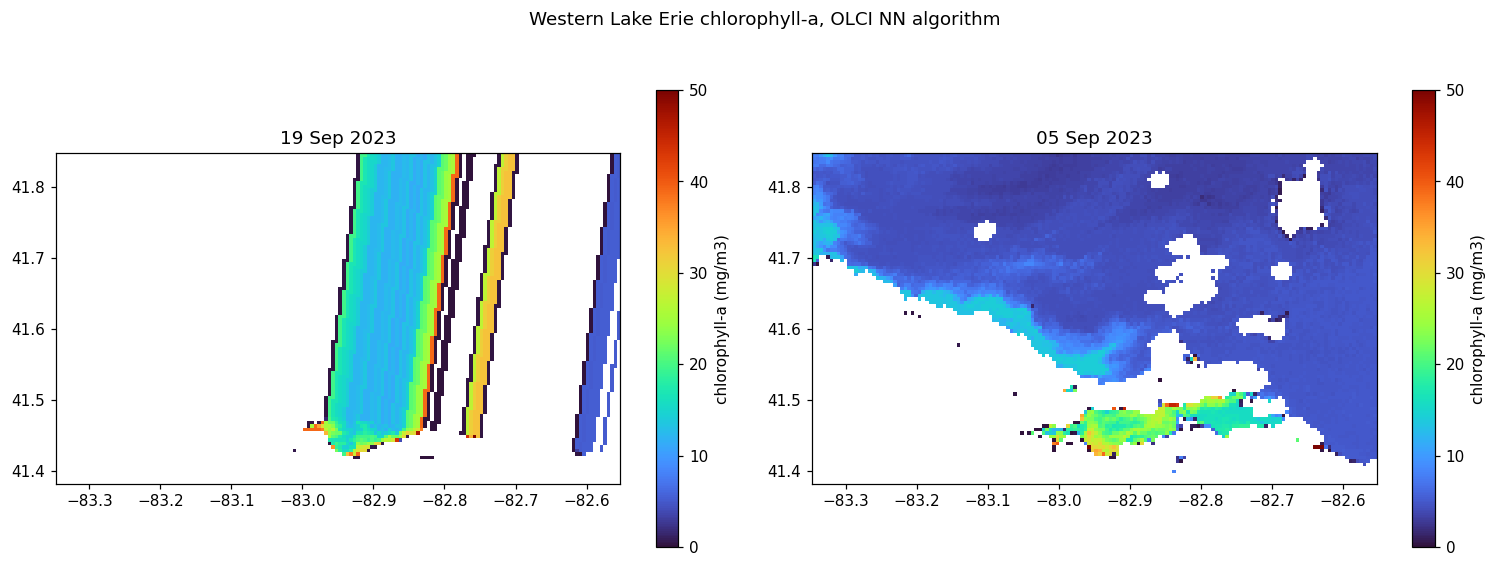

In [ ]:
# Create a figure with two side-by-side subplots to compare two chlorophyll-a maps
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Loop over each subplot axis, and each (date label, gridded chlorophyll data) pair in chl_maps
for ax, (label, grid) in zip(axes, chl_maps.items()):
    # Determine the extent (bounding box) of the grid for proper map display
    extent = [float(grid.x.min()), float(grid.x.max()), float(grid.y.min()), float(grid.y.max())]
    # Display the gridded chlorophyll-a data as an image with a color map and set color limits
    im = ax.imshow(
        grid.values,
        cmap="turbo",         # Use 'turbo' color map for vivid visualization
        vmin=0, vmax=50,      # Color bar scale: 0 to 50 mg/m³ chlorophyll-a
        extent=extent,
        origin="upper"
    )
    # Set title with formatted date
    ax.set_title(f"{pd.Timestamp(label):%d %b %Y}")
    # Add a colorbar to the plot for chlorophyll concentration
    plt.colorbar(im, ax=ax, shrink=0.85, label="chlorophyll-a (mg/m3)")

# Add a main title for the figure describing the dataset and algorithm used
plt.suptitle("Western Lake Erie chlorophyll-a, OLCI NN algorithm")
# Adjust layout to prevent overlap and display the plot
plt.tight_layout()
plt.show()  # draw

The 5 September pass has the better swath coverage of the two and shows the bloom's real
shape: chlorophyll concentrated along the southwestern shoreline near the Maumee River mouth
(Toledo, Ohio) at 15-30+ mg/m³, fading to under 5 mg/m³ in the clearer open water to the
northeast, exactly where western Lake Erie's blooms are known to originate. The 19 September
pass only grazes the AOI along its orbital track, leaving most of the frame empty; a small AOI
near the edge of even OLCI's 1270 km swath is not guaranteed full coverage on every pass.


## SLSTR land surface temperature

SLSTR's land surface temperature product works the same way as OLCI water: read, mask by flags
(cloud by default), convert units. We download one real scene over the Las Vegas valley, a
callback to the Landsat and Sentinel-2 notebooks' study area.


In [ ]:
# Define the bounding box for the Las Vegas valley region
VEGAS_BBOX = (-115.45, 35.95, -114.85, 36.40)
# Set the directory where the SLSTR LST data will be stored
LST_OUT = DATA / "s3_slstr_vegas"

if local_scenes(LST_OUT, ["LST_in.nc", "flags_in.nc", "geodetic_in.nc"]):  # downloaded before
    print("Reading the SLSTR LST scene already downloaded under", LST_OUT)  # use the local drive
elif ONLINE:  # not on disk yet: download when online
    # Search for Sentinel-3 SLSTR land surface temperature (LST) Level 2 scenes in the specified area and date range
    search = CATALOG.search(
        collections=["sentinel-3-slstr-lst-l2-netcdf"], 
        bbox=VEGAS_BBOX,
        datetime="2023-07-01/2023-07-15", 
        limit=10
    )
    # Take the first scene item returned by the search
    lst_item = next(iter(search.items()))
    # Set up a directory for this scene inside our output folder, creating it if needed
    scene_dir = LST_OUT / lst_item.id
    scene_dir.mkdir(exist_ok=True, parents=True)  # its folder
    # Specify the key asset files to download: LST data, pixel flags, and geolocation information
    assets = {
        "lst-in": "LST_in.nc", 
        "slstr-flags-in": "flags_in.nc",
        "slstr-geodetic-in": "geodetic_in.nc"
    }
    # Download each necessary asset file if it isn't already present locally
    for key, fname in assets.items():
        dest = scene_dir / fname  # local file
        if not dest.exists():  # download only if missing
            # Fetch the file using its online URL
            r = requests.get(lst_item.assets[key].href, timeout=60)
            r.raise_for_status()  # stop on an HTTP error
            dest.write_bytes(r.content)  # save it
    # Confirm which scene was downloaded and its date
    print(lst_item.id, lst_item.datetime, "downloaded")
else:
    # If not online, notify that the previously downloaded data will be reused
    print("Offline: reusing the scene already downloaded under", LST_OUT)

S3A_SL_2_LST_20230715T050921_20230715T051221_0180_101_105_0540 2023-07-15 05:10:50.742784+00:00 downloaded


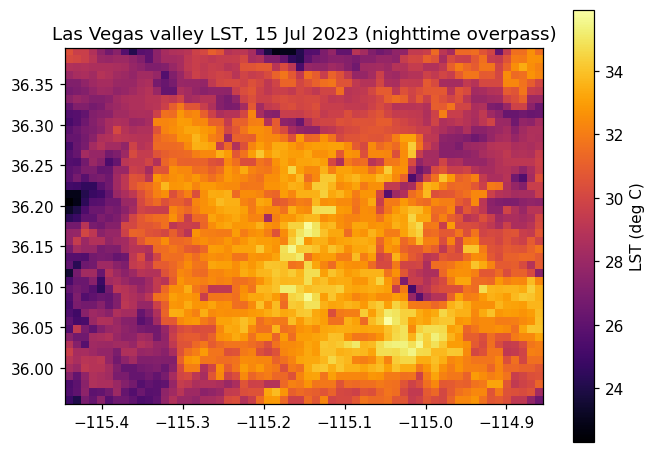

Mean 30.5 C, range 22.3 to 35.9 C


In [ ]:
# Find the first subdirectory in the LST output folder, which should correspond to the downloaded scene
lst_scene = next(p for p in LST_OUT.iterdir() if p.is_dir())

# Read the SLSTR land surface temperature dataset from this folder
lst_ds = s3.read_slstr_lst(lst_scene)

# Create a mask indicating valid pixels, filtering out those with uncertainty greater than 2.5 K
lst_valid = s3.slstr_lst_mask(lst_ds, max_uncertainty=2.5)

# Convert the LST data from Kelvin to Celsius and apply the validity mask; label the array as "lst"
lst_c = s3.kelvin_to_celsius(lst_ds["LST"]).where(lst_valid)
lst_c.name = "lst"  # its name

# Reproject and interpolate the swath data onto a regular grid for easier plotting and analysis
lst_grid = s3.swath_to_grid(
    lst_c, 
    lst_ds["longitude"], 
    lst_ds["latitude"],
    resolution=0.01, 
    bounds=VEGAS_BBOX
)

# Define plot extent for imshow: [xmin, xmax, ymin, ymax]
extent = [
    float(lst_grid.x.min()), float(lst_grid.x.max()),
    float(lst_grid.y.min()), float(lst_grid.y.max())
]

# Set up a matplotlib figure and axis for plotting the gridded LST data
fig, ax = plt.subplots(figsize=(7, 6))

# Plot LST as an image using the "inferno" colormap
im = ax.imshow(lst_grid.values, cmap="inferno", extent=extent, origin="upper")

# Add a title with the date of the satellite overpass
ax.set_title(f"Las Vegas valley LST, {lst_item.datetime:%d %b %Y} (nighttime overpass)")

# Add a colorbar, labeling it in degrees Celsius
plt.colorbar(im, ax=ax, shrink=0.85, label="LST (deg C)")

# Display the plot
plt.show()

# Print summary statistics: mean, minimum, and maximum LST (excluding NaN values)
print(
    f"Mean {float(np.nanmean(lst_grid.values)):.1f} C, "
    f"range {float(np.nanmin(lst_grid.values)):.1f} to {float(np.nanmax(lst_grid.values)):.1f} C"
)

This overpass crosses the valley at roughly 10 pm local time, not midday. SLSTR, like
most polar orbiters, has fixed day and night equator-crossing times rather than a choice of
local time. A nighttime LST composite is still useful: the urban-versus-desert temperature
contrast at night is often a cleaner signal of the urban heat island than the daytime image,
since built surfaces release stored daytime heat slowly while the surrounding desert cools fast.


## Active forest fires in western Canada

SLSTR's Level-2 fire product (`SL_2_FRP`) is a table of actively burning pixels, one row per fire, with fire radiative power (FRP) in megawatts. FRP is the rate at which those pixels were releasing energy at the time of the overpass. Mapped together, they are the active fire area.

Mid-May 2023 was the early peak of that year's Canadian wildfire season. Alberta declared a provincial state of emergency on 6 May, and large fires were burning in the boreal forest of west-central Alberta and northern Saskatchewan. This section downloads every SLSTR FRP scene that intersects those two provinces on 16 May 2023, keeps the pixels classified as vegetation fires, and maps them.

Two details of `FRP_in.nc` matter before `frp_to_points` returns one row per fire:

- The file mixes a one-dimensional fire table (dimension `fires`) with a two-dimensional flag image (`rows` by `columns`). Pass only the fire-table variables. Sending the whole dataset through `to_dataframe` tries to align those two grids.
- `classification` is a bit mask. Bit value `1` is `vegetation_fire`. The same mask also carries onshore gas flares, offshore flares, volcanoes and industrial sources. Alberta has persistent industrial hot spots, so the vegetation bit is what keeps this a forest-fire map. This product generation has no `FRP_MWIR_confidence` column for `frp_to_points` to filter on, so the classification mask does that job.

Neighbouring orbits, and the day and night overpasses, can see the same 1 km pixel more than once. After clipping to the provinces we keep the strongest FRP in each 0.01 degree cell (about 1 km, the SLSTR fire grid). `aggregate_frp` then sums those pixels onto a 0.2 degree grid so the burning area is readable at provincial scale. Black rings mark pixels with FRP of at least 150 MW.


In [10]:
# Alberta and Saskatchewan: the frame of the map below.
CANADA_BBOX = (-120.2, 49.0, -101.3, 56.8)
FRP_DAY = "2023-05-16"  # the day of the fire scenes
FRP_OUT = DATA / "s3_frp_canada_2023"  # folder for the FRP scenes

if local_scenes(FRP_OUT, ["FRP_in.nc"]):  # downloaded before
    print("Reading the FRP scenes already downloaded under", FRP_OUT)  # use the local drive
elif ONLINE:  # not on disk yet: download when online
    # Neighbouring orbits plus the day and night passes all cross this box,
    # so one calendar day is more than one scene.
    search = CATALOG.search(
        collections=["sentinel-3-slstr-frp-l2-netcdf"],
        bbox=CANADA_BBOX,
        datetime="2023-05-16T00:00:00Z/2023-05-17T00:00:00Z",
        limit=40,
    )
    n_scenes = 0  # number of scenes downloaded
    for it in search.items():  # every found item
        # keep only that day and items with an FRP file
        if it.datetime.date().isoformat() != FRP_DAY or "frp-in" not in it.assets:
            continue
        scene_dir = FRP_OUT / it.id  # its folder
        scene_dir.mkdir(exist_ok=True, parents=True)  # create it
        dest = scene_dir / "FRP_in.nc"  # local file
        if not dest.exists():  # download only if missing
            r = requests.get(it.assets["frp-in"].href, timeout=120)  # download it
            r.raise_for_status()  # stop on an HTTP error
            dest.write_bytes(r.content)  # save it
        n_scenes += 1  # count it
        print(it.id, "downloaded")  # progress
    print(n_scenes, "scenes for", FRP_DAY)  # total
else:
    print("Offline: reusing the scenes already downloaded under", FRP_OUT)  # offline

S3B_SL_2_FRP_20230516T191818_20230516T192118_0179_079_270_1980 downloaded
S3A_SL_2_FRP_20230516T181926_20230516T182226_0179_099_027_2160 downloaded
S3A_SL_2_FRP_20230516T181626_20230516T181926_0179_099_027_1980 downloaded
S3B_SL_2_FRP_20230516T174019_20230516T174319_0179_079_269_2160 downloaded
S3B_SL_2_FRP_20230516T173719_20230516T174019_0179_079_269_1980 downloaded
S3A_SL_2_FRP_20230516T163826_20230516T164126_0179_099_026_2160 downloaded
S3A_SL_2_FRP_20230516T163526_20230516T163826_0179_099_026_1980 downloaded
S3A_SL_2_FRP_20230516T061131_20230516T061431_0179_099_020_0900 downloaded
S3A_SL_2_FRP_20230516T060831_20230516T061131_0179_099_020_0720 downloaded
S3B_SL_2_FRP_20230516T053224_20230516T053524_0179_079_262_0900 downloaded
S3B_SL_2_FRP_20230516T052924_20230516T053224_0179_079_262_0720 downloaded
S3A_SL_2_FRP_20230516T043032_20230516T043332_0179_099_019_0900 downloaded
S3A_SL_2_FRP_20230516T042732_20230516T043032_0179_099_019_0720 downloaded
S3B_SL_2_FRP_20230516T035125_20230516T

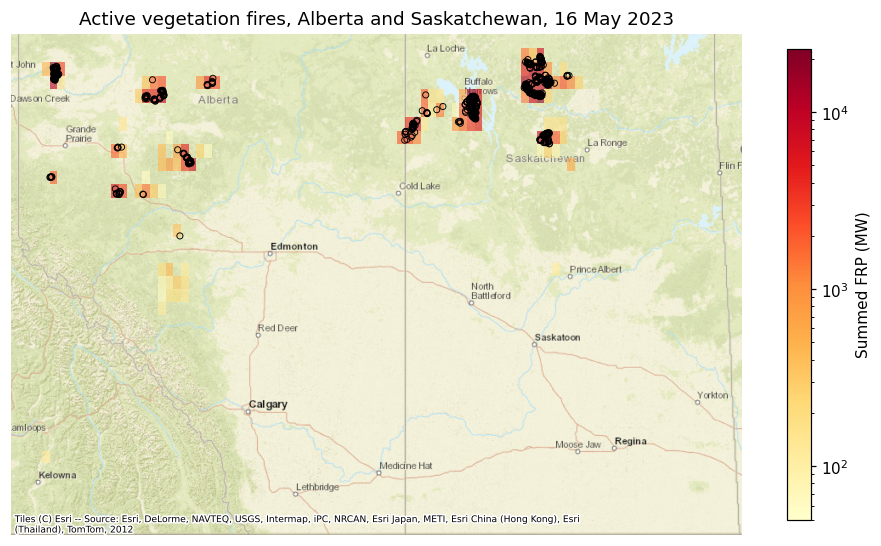

14 scenes with fires, 6440 vegetation-fire pixels after removing repeats, strongest pixel 1556 MW


In [12]:
import geopandas as gpd  # vector data
import contextily as cx  # web-map basemaps
from shapely.geometry import box  # rectangle geometry
from matplotlib.colors import LogNorm  # logarithmic colour scale

frames = []  # fire points of every scene
for scene in sorted(p for p in FRP_OUT.iterdir() if p.is_dir()):  # every FRP scene folder
    ds = s3.read_slstr_frp(scene)  # read the fire radiative power product
    # Skip scenes whose swath missed every fire, and drop the 2-D flag image
    # so the table stays one row per fire.
    if ds.sizes.get("fires", 0) == 0:
        continue
    # variables with one value per fire
    fire_vars = [name for name in ds.data_vars if ds[name].dims == ("fires",)]
    frames.append(s3.frp_to_points(ds[fire_vars]))  # fires as points

if not frames:  # no fires found
    raise FileNotFoundError(f"No FRP scenes with fires under {FRP_OUT}")  # stop with a clear message

# all fires as one GeoDataFrame
fires = gpd.GeoDataFrame(pd.concat(frames, ignore_index=True), geometry="geometry", crs=4326)

# Bit 1 of classification is vegetation_fire. Gas flares and industrial
# sources use other bits and stay out of this map.
veg = fires[(fires["classification"].astype(int) & 1) != 0].copy()
west, south, east, north = CANADA_BBOX  # the study box
veg = veg.cx[west:east, south:north].copy()  # keep fires inside it

# Repeated views of the same ~1 km pixel: keep the strongest FRP.
veg["gx"] = (veg.geometry.x // 0.01) * 0.01
veg["gy"] = (veg.geometry.y // 0.01) * 0.01  # 0.01 degree grid row
# keep the strongest fire per grid cell
veg = veg.sort_values("FRP_MWIR", ascending=False).drop_duplicates(["gx", "gy"])

RES = 0.2  # degrees, about 15-20 km, readable on a provincial map
grid = s3.aggregate_frp(veg, resolution=RES, agg="sum")  # total FRP per grid cell
cells = gpd.GeoDataFrame(  # the cells as polygons
    {"FRP_MWIR": grid.to_numpy()},
    geometry=[box(gx, gy, gx + RES, gy + RES) for gy, gx in grid.index],
    crs=4326,
)
cells = cells[cells["FRP_MWIR"] >= 50]  # cells with at least 50 MW
hot = veg[veg["FRP_MWIR"] >= 150]  # single fires of at least 150 MW

fig, ax = plt.subplots(figsize=(8.6, 7.2))  # one panel
cells.to_crs(3857).plot(  # the cells in Web Mercator, coloured by FRP
    ax=ax,
    column="FRP_MWIR",
    cmap="YlOrRd",
    norm=LogNorm(vmin=50, vmax=float(cells["FRP_MWIR"].max())),
    alpha=0.62,
    legend=True,
    legend_kwds={"label": "Summed FRP (MW)", "shrink": 0.62},
)
hot.to_crs(3857).plot(  # the hottest fires on top
    ax=ax, facecolor="none", edgecolor="black", linewidth=0.6, markersize=16, zorder=3
)
frame = gpd.GeoSeries([box(west, south, east, north)], crs=4326).to_crs(3857)  # the study box in Web Mercator
minx, miny, maxx, maxy = frame.total_bounds  # its bounds
ax.set_xlim(minx, maxx)  # x extent
ax.set_ylim(miny, maxy)  # y extent
# The default OpenStreetMap tile server blocks this client. Esri's street map
# still carries the town names used to read the clusters.
cx.add_basemap(ax, source=cx.providers.Esri.WorldStreetMap, attribution_size=6)
ax.set_axis_off()  # no axes
ax.set_title("Active vegetation fires, Alberta and Saskatchewan, 16 May 2023")  # title
plt.tight_layout()  # arrange
plt.show()  # draw

print(  # summary of the fires
    f"{len(frames)} scenes with fires, "
    f"{len(veg)} vegetation-fire pixels after removing repeats, "
    f"strongest pixel {float(veg['FRP_MWIR'].max()):.0f} MW"
)

On 16 May 2023 the active vegetation pixels sit in the boreal forest. One cluster runs through west-central Alberta, from the country north of Grande Prairie through Fox Creek toward Whitecourt. The other is in northern Saskatchewan, around Buffalo Narrows, La Loche and La Ronge. The prairie from Red Deer south through Medicine Hat and Regina is quiet on this date. The colour scale is logarithmic, so fires of a few hundred megawatts and the largest cell sums (well above 10,000 MW) can be read on the same map. A dark cell is a sum of FRP over about 0.2 degrees: one intense fire, or many neighbouring pixels. The black rings are the individual pixels at or above 150 MW inside that area.


## Terrestrial chlorophyll indices, in and out of their domain

`geolattice.rsense` registers two indices built on OLCI's red-edge bands: MCI, designed for turbid
and coastal waters (so appropriate for Lake Erie), and OTCI, the *terrestrial* chlorophyll index,
designed for vegetated land. Both run on the same three bands (`oa10`, `oa11`, `oa12`); only one
of them is appropriate for a lake scene.


In [14]:
# the MCI and OTCI index definitions
cat = rs.optical.list_indices().set_index("name").loc[["MCI", "OTCI"], ["long_name", "bands", "reference"]]
cat  # show them

,long_name,bands,reference
name,,,
MCI,Maximum Chlorophyll Index,"oa11, oa10, oa12",Gower et al. 2005; Sentinel-3 OLCI bands 10/11...
OTCI,OLCI Terrestrial Chlorophyll Index,"oa12, oa11, oa10",Dash & Curran 2004 (as MTCI); Sentinel-3 OLCI ...


In [16]:
# Explanation:
# The code below selects a specific OLCI (Ocean and Land Colour Imager) scene by date, reads critical bands and chlorophyll from the data, applies a water mask to exclude unwanted pixels, then computes two chlorophyll indices—MCI (Maximum Chlorophyll Index) and OTCI (OLCI Terrestrial Chlorophyll Index). Finally, it prints summary statistics for both indices.
#
# 1. OLCI scene folders are labeled alphabetically by satellite, not by date. To get the scene from "2023-09-05", it searches scene_dirs for that date (using scene_date).
oa_scene = next(d for d in scene_dirs if scene_date(d) == "2023-09-05")

# 2. Reads OLCI water product data for the selected scene. Only the neural-network chlorophyll ('chl_nn') and three red-edge bands ('oa10', 'oa11', 'oa12') are loaded.
refl_ds = s3.read_olci_water(oa_scene, variables=["chl_nn", "oa10", "oa11", "oa12"])

# 3. Applies a water mask to the three red-edge bands (excluding features defined in ERIE_EXCLUDE),
#    resulting in a cleaned reflectance dataset used for index calculation.
clean_refl = refl_ds[["oa10", "oa11", "oa12"]].where(
    s3.olci_water_mask(refl_ds["wqsf"], exclude=ERIE_EXCLUDE))

# 4. Computes the MCI and OTCI indices using the cleaned reflectance data.
mci = clean_refl.rs.index("MCI")
otci = clean_refl.rs.index("OTCI")  # OLCI Terrestrial Chlorophyll Index

# 5. Prints basic statistics:
#    - For MCI: mean value and data range (minimum to maximum), ignoring any missing values (NaN).
#    - For OTCI: mean, median, and range (rounded for clarity), ignoring missing values.
print(f"MCI:  mean {float(mci.mean(skipna=True)):.4f}, "
     f"range {float(mci.min(skipna=True)):.4f} to {float(mci.max(skipna=True)):.4f}")
print(f"OTCI: mean {float(otci.mean(skipna=True)):.2f}, "  # its statistics
     f"median {float(otci.median(skipna=True)):.2f}, "
     f"range {float(otci.min(skipna=True)):.0f} to {float(otci.max(skipna=True)):.0f}")

MCI:  mean -0.0006, range -0.0376 to 0.0854
OTCI: mean 0.26, median 0.04, range -3070 to 3313


MCI stays in a small, physically sensible range. OTCI does not: its formula divides by
`oa11 - oa10`, the slope across vegetation's red edge, which is well-behaved over leaves but
near zero (and noisy in sign) over water, since open water has no red-edge feature at all. A
handful of near-zero denominators blow the statistic up to thousands in either direction. This
is not a bug in the formula, it is what happens when an index built on one physical assumption
(a reflecting canopy) is pointed at a target where that assumption does not hold. The general
lesson from the *SLSTR land surface temperature* section of the Sentinel-2 notebook (NDVI saturating over dense canopy) in reverse:
here the index is *undefined-feeling* rather than *insensitive*, which can be the more
dangerous failure mode, since it still returns a number.


## Summary, exercises and references

**Key ideas**

- Sentinel-3 bundles four instruments (OLCI, SLSTR, SRAL, MWR) covering ocean colour, surface
  temperature, fire and sea-surface height, each with its own NetCDF product family and flags.
- Every quality flag follows the same CF `flag_masks`/`flag_meanings` convention; decode it from
  the variable's own metadata rather than a hardcoded bit position.
- Real product files do not always use the lowercase, stem-matching variable names their own
  documentation suggests: `trsp.nc` holds `KD490_M07`, `rc_gifapar.nc` holds two bands, not one.
  Check against a real download rather than trusting an assumed name.
- A standard ocean flag (`LAND`) can misfire over turbid inland water; know your AOI before you
  trust a default exclusion list.
- Log-scaled products (chlorophyll, TSM) must be back-transformed before averaging or mapping.
- Resample swath data to a grid once, at the end, after masking and unit conversion.
- An index is only as good as the physical assumption behind it; pointed outside its domain, it
  can fail by returning an extreme, confident-looking number rather than an obviously missing one.
- SLSTR FRP is a table of burning pixels, not a raster. Keep the vegetation-fire bit of
  `classification` before treating a hotspot as a forest fire, and collapse repeated views of
  the same pixel before summing.

**`geolattice.rsense` functions used:** `geolattice.rsense.optical.sensors.sentinel3.read_olci_water`,
`olci_water_mask`, `read_slstr_lst`, `slstr_lst_mask`, `read_slstr_frp`, `frp_to_points`,
`aggregate_frp`, `decode_flags`, `flag_mask`,
`log_to_linear`, `kelvin_to_celsius`, `swath_to_grid`, `rs.optical.list_indices`, `.rs.index`.

**Exercises**

1. Repeat the *Downloading a real OLCI water product* section for a different OLCI WFR collection date and compare the bloom's extent.
2. Use `read_olci_land` to retrieve FAPAR (`gifapar`) and OTCI over a real vegetated AOI (for
   example, farmland away from open water) and confirm OTCI behaves sensibly there.
3. Build a short chlorophyll time series over a full bloom season (June-October) and locate its
   peak, mirroring the phenology work in the optical chapter's (07_02) MODIS and Sentinel-2 notebooks.
4. Repeat the *Active forest fires in western Canada* section for a later date in the 2023 season (for example 15 August) and compare
   where the vegetation fires sit. Split `Day_night` before the 1 km collapse and see which
   pass detects more pixels.
5. Compare `chl_oc4me` (open-ocean algorithm) and `chl_nn` (neural-network algorithm) over the
   same Lake Erie scene. Which handles this turbid water better?

**Next:** Notebook 07_02_07 works with Sentinel-5P and Sentinel-5.
